# Linear Models

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression, make_classification
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import train_test_split

## Linear Regression

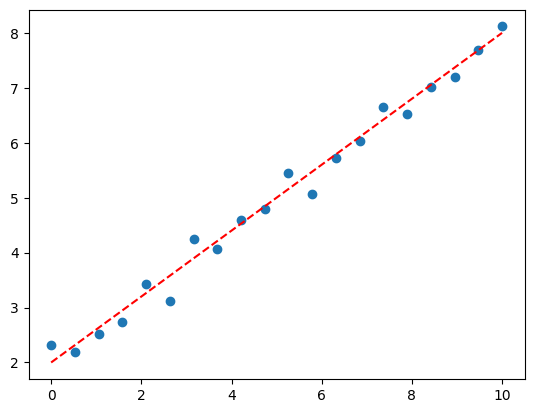

In [2]:
np.random.seed(1)
X = np.linspace(0, 10, num=20)
y = 2 + 0.6 * X + np.random.normal(scale=0.2, size=X.shape[0])
plt.scatter(X, y)
plt.plot(X, 2 + 0.6 * X, 'r--');

**Linear Regression** is an algorithm that finds the best fit line (in case of simple linear regression) or best fit curve (**Polynomial Regression**) to a set of datapoints. In higher dimensions, the algorithm finds the best fit hyperplane.

In order to find the best fit line, we minimize the **Mean Squared Error**.

$$
MSE = \frac{1}{N}\sum_i^N (\hat{y_i} - y_i)^2
$$

where $\hat{y_i}$ is our prediction, $y_i$ is the actual value and $N$ is the number of samples in our data. Basically, we take the distance of the point from the line/hyperplane and square it, then take the average.

Squaring solves two issues:
1. If we used the distances themselves, points above the line would have a positive distance and points below the line would have a negative distance and summing them could cancel them out. In extreme cases, we could get an error of $0$ despite the line being a very poor fit. Squaring them makes all distances positive.
2. If we used the absolute value, optimization would be difficult. The absolute value is not a smooth function and has a corner at the minimum, so it's not differentiable at the minimum (this is sometimes circumvented by using **Huber Loss**, which behaves like the absolute value, but is smooth near the minimum). Using the square of the residuals makes this a smooth convex problem with a global minimum that's differentiable everywhere.

To optimize the problem, we will use **Gradient Descent**. This is an optimization algorithm that uses the derivative of the function that's being optimized to update the estimated parameters of the model by taking a small step in the direction of the downward slope, eventually reaching the minimum.

The general formula for a Linear Regression model is

$$
\hat{y} = \beta_0 + \beta_1x_1 + \beta_2x_2 + ... + \beta_nx_n
$$

where $n$ is the number of parameters, $x_1 ... x_n$ are the features and $\beta_1 ... \beta_n$ are the estimated coefficients (weights).

Taking the simplest possible model, which is the best fit line in a 2D space (single feature), this becomes:

$$
\hat{y} = \beta_0 + \beta_1x_1
$$

Our formula for the optimization problem then becomes:

$$
\min_{\beta_0, \beta_1} J(\beta_0, \beta_1) = \frac{1}{2N}\sum_i^N (\beta_0 + \beta_1x_1^{(i)} - y^{(i)})^2
$$

This means we want to find the parameters $\beta_0$ and $\beta_1$ that minimize MSE. In practice, we often divide by $2N$ in order to make the derivatives nicer.

We initialize the parameters randomly and update them repeatedly by calculating the value of the derivative with respect to each parameter, then subracting it from the parameter:

$$
\beta_0 := \beta_0 - \eta \frac{\partial{J}}{\partial{\beta_0}}
$$

$$
\beta_1 := \beta_1 - \eta \frac{\partial{J}}{\partial{\beta_1}}
$$

where $\eta$ is the learning rate. We keep updating until the loss $J$ stops improving (the improvement is less than some parameter $\epsilon$).

The partial derivative of $J$ with respect to the intercept $\beta_0$ is:

$$
\begin{align}
\frac{\partial{J}}{\partial{\beta_0}} & = \frac{\partial}{\partial{\beta_0}} \frac{1}{2N}\sum_i^N (\beta_0 + \beta_1x_1^{(i)} - y^{(i)})^2 \\
& = \frac{1}{2N}\sum_i^N 2(\beta_0 + \beta_1x_1^{(i)} - y^{(i)}) \\
& = \frac{1}{N}\sum_i^N (\beta_0 + \beta_1x_1^{(i)} - y^{(i)})
\end{align}
$$

The partial derivative of $J$ with respect to the slope $\beta_1$ is:

$$
\begin{align}
\frac{\partial{J}}{\partial{\beta_1}} & = \frac{\partial}{\partial{\beta_1}} \frac{1}{2N}\sum_i^N (\beta_0 + \beta_1x_1^{(i)} - y^{(i)})^2 \\
& = \frac{1}{2N}\sum_i^N 2(\beta_0 + \beta_1x_1^{(i)} - y^{(i)})x_1^{(i)} \\
& = \frac{1}{N}\sum_i^N (\beta_0 + \beta_1x_1^{(i)} - y^{(i)})x_1^{(i)}
\end{align}
$$

If we have more features, we extend the formulas analogously with $\beta_2x_2 ... \beta_nx_n$.

In case of **Polynomial Regression**, the math works the same, it's just that the features can contain polynomial terms ($x_1^2$, $x_1^3$) and interaction terms ($x_1x_2$). The model is still linear in the coefficients:

$$
\hat{y} = \beta_0 + \beta_1x_1 + \beta_2x_1^2 + ...
$$

One final thing we need to do is transform this into vector and matrix notation so that we can solve for all coefficients at once, avoiding for loops and taking advantage of fast processing. Our loss function becomes:

$$
J(w, b) = \frac{1}{2N}(Xw + b - y)^T(Xw + b - y) = \frac{1}{2N}(Xw + b - y)^2
$$

where $X$ is our data ($N$ samples x $n$ features), $w$ is a vector of coefficients ($\beta_1 ... \beta_n$), $b$ is the y-intercept (same as $\beta_0$ previously) and y is a vector of true values ($y_1 ... y_N$).

In [3]:
class LinReg:
    def __init__(self, eps=1e-6, lr=0.01, max_iter=10000, seed=None):
        self.eps = eps
        self.max_iter = max_iter
        self.lr = lr
        self.rng = np.random.default_rng(seed)
        self.intercept = None
        self.coefs = []
        self.losses = []
        
    def fit(self, X, y):
        assert X.ndim == 2
        assert y.ndim == 1

        # reset variables
        self.intercept = None
        self.coefs = []
        self.losses = []

        y = y.reshape(-1, 1)
        # initialize intercept and coefficients
        b = self.rng.random(size=1)
        w = self.rng.random(size=X.shape[1])
        if w.ndim == 1:
            w = w.reshape(-1, 1)

        prev_loss = np.inf
        i = 0

        while True:
            # compute predictions
            y_hat = X @ w + b
            y_diff = y_hat - y
            
            # compute loss and update b and w based on gradients
            loss = self._loss(X, y_diff, w)
            self.losses.append(loss.item())
            w_prev = np.copy(w)
            b, w = self._update_weights(X, y_diff, b, w)
            
            # exit if we've converged or we've reached the maximum number of iterations
            if np.abs(prev_loss - loss) < self.eps or (i >= self.max_iter if self.max_iter is not None else False):
                self.intercept = b
                self.coefs = w
                break
            if loss < prev_loss:
                prev_loss = loss
            i += 1
            
        return self

    def predict(self, X):
        assert X.ndim == 2
        y_hat = X @ self.coefs + self.intercept
        return y_hat.reshape(1, -1)[0]

    def _loss(self, X, y_diff, w):
        loss = np.mean(y_diff ** 2) / 2
        return loss
        
    def _update_weights(self, X, y_diff, b, w):
        b_grad = np.mean(y_diff)
        w_grad = np.mean(X * y_diff, axis=0).reshape(-1, 1)
        w = w - self.lr * w_grad
        b = b - self.lr * b_grad
        return b, w

#### Test Unregularized Linear Regression

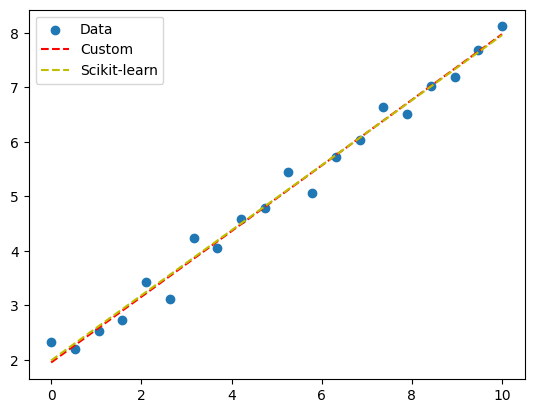

In [4]:
np.random.seed(1)
X = np.linspace(0, 10, num=20)
y = 2 + 0.6 * X + np.random.normal(scale=0.2, size=X.shape[0])
X = X.reshape(-1, 1)

lr = LinReg(seed=1).fit(X, y)
lr2 = LinearRegression().fit(X, y)
plt.scatter(X, y)
plt.plot(X, X @ lr.coefs + lr.intercept, 'r--');
plt.plot(X, X @ lr2.coef_ + lr2.intercept_, 'y--');
plt.legend(['Data', 'Custom', 'Scikit-learn'])

In [5]:
X, y = make_regression(n_samples=1000, n_features=3, noise=20, random_state=42)
lr = LinReg(seed=1).fit(X, y)
lr2 = LinearRegression().fit(X, y)

In [6]:
lr.intercept, lr2.intercept_

(array([-0.09148995]), np.float64(-0.09484857511295974))

In [7]:
lr.coefs, lr2.coef_

(array([[98.44027645],
        [83.62468271],
        [25.89203523]]),
 array([98.44521371, 83.63369804, 25.89355072]))

### Regularization

Regularization techniques are ways of constraining model complexity (magnitude of coefficients) so that we prevent overfitting (memorizing the training data). This is accomplished by shrinking the coefficients close to 0 (**Ridge Regression**) or shrinking them to 0 and thereby removing the influence of the feature entirely (**Lasso Regression**).

We accomplish this by introducing a penalty on the size of the coefficients. This penalty is added to the cost function $J$, forcing the model to minimize both the error on the data, as well as the magnitude of the coefficients. For **Ridge Regression** the loss function becomes:

$$
J(w, b) = \frac{1}{2N}(Xw + b - y)^2 + \frac{\lambda}{2N} \sum_{i}^p w_i^2
$$

where $\lambda$ is a parameter telling the model how much emphasis to put on the penalty and $p$ are the features of the model.

For **Lasso Regression**:

$$
J(w, b) = \frac{1}{2N}(Xw + b - y)^2 + \lambda \sum_{i}^p |w_i|
$$

Next, we compute the derivatives of the loss function. For **Ridge Regression**, this is easy:

$$
\frac{\partial{J}}{\partial{w}} = \frac{1}{N}X^T(Xw + b - y) + \frac{\lambda}{N} \sum_{i}^p w_i
$$

For **Lasso Regression**, we face a problem. The absolute value is not differentiable at $0$, so there is no way to simply calculate the derivative. In practice, we first calculate the gradient of the squared error loss and then adjust. There are multiple ways of adjusting the gradient, one of them being the **Soft-Threshold Operator**. We update the weights $w$ as follows:

$$
\frac{\partial{J}}{\partial{w}} = \frac{1}{N}X^T(Xw + b - y)
$$

$$
w := w - \eta \frac{\partial{J}}{\partial{w}}
$$

$$
w := S(w)
$$

where $S$ is the **Soft-Threshold Operator**:

$$
S(w) = sign(w) \max(|z| - \eta \lambda, 0)
$$

In [8]:
class RidgeLinReg(LinReg):
    def __init__(self, lambda_=1, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.lambda_ = lambda_

    def _loss(self, X, y_diff, w):
        # add the penalty to the squared error loss
        loss = super()._loss(X, y_diff, w) + self.lambda_ / X.shape[0] / 2 * (w ** 2).sum()
        return loss

    def _update_weights(self, X, y_diff, b, w):
        b_grad = np.mean(y_diff)
        # add the derivative of the penalty to the gradient
        w_grad = np.mean(X * y_diff, axis=0).reshape(-1, 1) + self.lambda_ / X.shape[0] * w
        w = w - self.lr * w_grad
        b = b - self.lr * b_grad
        return b, w

class LassoLinReg(LinReg):
    def __init__(self, lambda_=1, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.lambda_ = lambda_

    def _loss(self, X, y_diff, w):
        loss = np.mean(y_diff ** 2) / 2 + self.lambda_ * np.abs(w).sum()
        return loss

    def _update_weights(self, X, y_diff, b, w):
        b_grad = np.mean(y_diff)
        w_grad = np.mean(X * y_diff, axis=0).reshape(-1, 1)
        w = w - self.lr * w_grad
        w = self._soft_threshold(w)
        b = b - self.lr * b_grad
        return b, w

    def _soft_threshold(self, z):
        return np.sign(z) * np.maximum(np.abs(z) - self.lr * self.lambda_, 0)

#### Test Ridge Regression

In [9]:
X, y = make_regression(n_samples=1000, n_features=4, noise=20, random_state=42, n_informative=2)
lr = RidgeLinReg(lambda_=50, seed=1).fit(X, y)
lr2 = Ridge(alpha=50).fit(X, y)

In [10]:
lr.intercept, lr2.intercept_

(array([-0.8926255]), np.float64(-0.8953376699468979))

In [11]:
lr.coefs, lr2.coef_

(array([[-0.06164332],
        [ 8.22763622],
        [ 0.39491175],
        [45.97971239]]),
 array([-0.06051667,  8.22832706,  0.39697309, 45.98935155]))

#### Test Lasso Regression

In [12]:
X, y = make_regression(n_samples=1000, n_features=4, noise=20, random_state=42, n_informative=2)
lr = LassoLinReg(lambda_=2, seed=1).fit(X, y)
lr2 = Lasso(alpha=2).fit(X, y)

In [13]:
lr.intercept, lr2.intercept_

(array([-0.86897362]), np.float64(-0.87134051998399))

In [14]:
lr.coefs, lr2.coef_

(array([[-0.        ],
        [ 6.6594402 ],
        [ 0.        ],
        [46.30062706]]),
 array([-0.        ,  6.65974251,  0.        , 46.31101595]))

## Logistic Regression

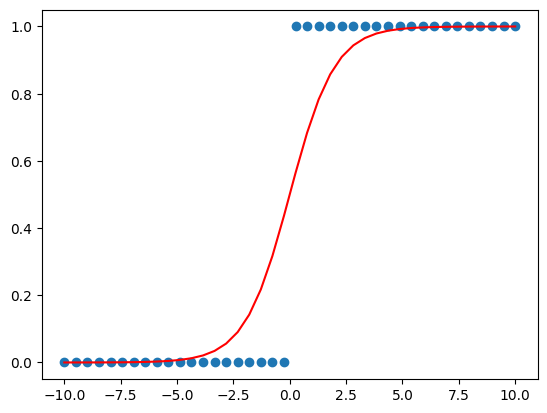

In [324]:
np.random.seed(1)
X = np.linspace(-10, 10, num=40)
plt.scatter(X, np.where(X <= 0, 0, 1))
plt.plot(X, 1 / (1 + np.exp(-X)), color='r');

**Logistic Regression** is a statistical method used to estimate the probability of a binary outcome. It is a way of fitting a line to a binary classification problem. We do this by employing the **sigmoid function** which squishes all outputs to the interval $(0, 1)$:

$$
g(z) = \frac{1}{1 + e^{-z}} = \frac{1}{1 + e^{-(wX + b)}}
$$

The exponent $z$ is a linear function of the features $X$.

To find the minimum of this function, we cannot use MSE as our loss, instead we need to find a convex function that we can optimize using Gradient Descent:

$$
L(g(z), y) = 
    \begin{cases}
      -\log(g(z)) & \text{if $y_i = $1}\\
      -\log(1 - g(z)) & \text{if $y_i = $0}
    \end{cases}
$$

where $y_i$ is the class that the sample $i$ belongs to.

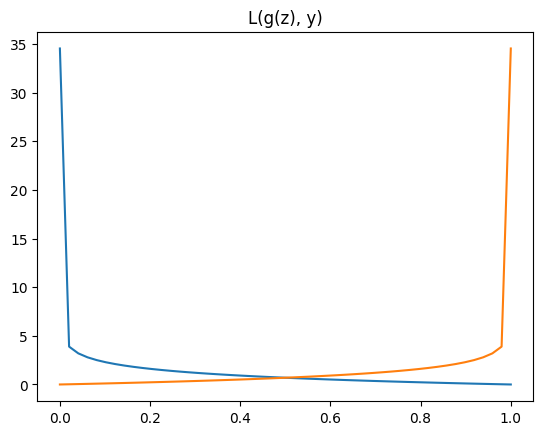

In [325]:
X = np.linspace(0, 1)
X = np.clip(X, 1e-15, 1 - 1e-15) 
plt.plot(X, -np.log(X))
plt.plot(X, -np.log(1 - X))
plt.title('L(g(z), y)');

The cost function, called **Binary Cross-Entropy**, thus becomes:

$$
J(w, b) = -\frac{1}{N} \sum_{i=1}^{N} (y^{(i)} \log(g(z)) + (1 - y^{(i)}) \log(1 - g(z)))
$$

The Gradient Descent algorithm is the same as for **Linear Regression**:

$$
b := b - \eta \frac{\partial{J}}{\partial{b}}
$$

$$
w := w - \eta \frac{\partial{J}}{\partial{w}}
$$

We can compute the derivatives using the chain rule:

$$
\begin{align}
J(w, b) &= -(y^{(i)} \log(a) + (1 - y^{(i)}) \log(1 - a)) \\
a &= g(z) = \frac{1}{1 + e^{-z}} \\
z &= wx + b
\end{align}
$$

We omit the summation and $\frac{1}{N}$ in the above and the following for clarity.

Then

$$
\frac{\partial{J}}{\partial{w}} = \frac{\partial{J}}{\partial{a}} \frac{\partial{a}}{\partial{z}} \frac{\partial{z}}{\partial{w}}
$$

$$
\frac{\partial{z}}{\partial{w}} = \frac{\partial{wx + b}}{\partial{w}} = x
$$

$$
\frac{\partial{a}}{\partial{z}} = \frac{\partial}{\partial{z}} (\frac{1}{1 + e^{-z}}) = \frac{e^{-z}}{(1 + e^{-z})^2}
$$

We can express $\frac{\partial{a}}{\partial{z}}$ in terms of $a$, which will be useful later:

$$
\begin{align}
a &= \frac{1}{1 + e^{-z}} \\
a^2 &= \frac{1}{(1 + e^{-z})^2} \\
\frac{1}{a} &= 1 + e^{-z} \\
e^{-z} &= \frac{1}{a} - 1 = \frac{1-a}{a} \\
\frac{\partial{a}}{\partial{z}} &= \frac{e^{-z}}{(1 + e^{-z})^2} = a^2 \frac{1 - a}{a} = (1-a)a
\end{align}
$$

Now we compute $\frac{\partial{J}}{\partial{a}}$:

$$
\begin{align}
\frac{\partial{J}}{\partial{a}} &= \frac{\partial}{\partial{a}} -(y\log(a) + (1-y)\log(1-a)) \\
&= -(\frac{y}{a} + \frac{1-y}{1-a} (-1)) \\
&= -\frac{y}{a} + \frac{1-y}{1-a}
\end{align}
$$

This gives:

$$
\begin{align}
\frac{\partial{J}}{\partial{a}} \frac{\partial{a}}{\partial{z}} \frac{\partial{z}}{\partial{w}} &= (-\frac{y}{a} + \frac{1-y}{1-a})a(1-a) \\
&= (a-y)x
\end{align}
$$

For $\frac{\partial{L}}{\partial{b}}$ everything is the same except $\frac{\partial{z}}{\partial{b}} = 1$, so we get:

$$
\frac{\partial{L}}{\partial{b}} = a - y
$$

Now we substitute back, add the summation and the fraction $\frac{1}{N}$:

$$
\frac{\partial{J}}{\partial{w}} = \frac{1}{N} \sum_{i=1}^{N} (g(z^{(i)}) - y^{(i)})x^{(i)}
$$

$$
\frac{\partial{J}}{\partial{b}} = \frac{1}{N} \sum_{i=1}^{N} (g(z^{(i)}) - y^{(i)})
$$

where $z^{(i)} = wx^{(i)} + b$.

### Regularization

Just like in the case of **Linear Regression**, we can regularize the **Logistic Regression**. Since we're working with linear models, the formulas for the penalties and the derivatives are the same. For L1 regularization, we use the **Soft-Threshold Operator** as before.

In [362]:
class LogReg:
    def __init__(self, eps=1e-7, lr=0.01, max_iter=10000, seed=None):
        self.eps = eps
        self.max_iter = max_iter
        self.lr = lr
        self.rng = np.random.default_rng(seed)
        self.intercept = None
        self.coefs = []
        self.losses = []
        
    def fit(self, X, y):
        assert X.ndim == 2
        assert y.ndim == 1
        
        # reset variables
        self.intercept = None
        self.coefs = []
        self.losses = []

        y = y.reshape(-1, 1)
        # initialize intercept and coefficients
        b = self.rng.random(size=1)
        w = self.rng.random(size=X.shape[1])
        
        if w.ndim == 1:
            w = w.reshape(-1, 1)

        prev_loss = np.inf
        i = 0

        while True:
            # compute predictions
            y_hat = X @ w + b
            g = self._sigmoid(y_hat)
            # compute loss and update b and w based on gradients
            loss = self._loss(X, y, g, w)
            b, w = self._update_weights(X, y, g, b, w)
            self.losses.append(loss.item())
            
            # exit if we've converged or we've reached the maximum number of iterations
            if np.abs(prev_loss - loss) < self.eps or (i >= self.max_iter if self.max_iter is not None else False):
                self.intercept = b
                self.coefs = w
                break
            if loss < prev_loss:
                prev_loss = loss
            i += 1
        
        return self

    def predict(self, X, thr=0.5):
        y_hat = X @ self.coefs + self.intercept
        g = self._sigmoid(y_hat)
        return np.where(g <= thr, 0, 1)

    def _loss(self, X, y, g, w):
        N = X.shape[0]
        loss = -np.sum(y * np.log(g) + (1 - y) * np.log(1 - g)) / N
        return loss

    def _update_weights(self, X, y, g, b, w):
        N = X.shape[0]
        b_grad = np.sum(g - y) / N
        b = b - self.lr * b_grad
        w_grad = (X.T @ (g - y)) / N
        w = w - self.lr * w_grad
        return b, w
        
    def _sigmoid(self, x):
        g = 1 / (1 + np.exp(-x))
        # need to clip the outputs so that we avoid feeding 0 into np.log
        return np.clip(g, 1e-15, 1 - 1e-15)

class RidgeLogReg(LogReg):
    def __init__(self, lambda_=1, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.lambda_ = lambda_

    def _loss(self, X, y, g, w):
        # add the penalty to the loss
        loss = super()._loss(X, y, g, w) + self.lambda_ / X.shape[0] / 2 * (w ** 2).sum()
        return loss

    def _update_weights(self, X, y, g, b, w):
        N = X.shape[0]
        b_grad = np.sum(g - y) / N
        b = b - self.lr * b_grad
        w_grad = (X.T @ (g - y)) / N + self.lambda_ / X.shape[0] * w
        w = w - self.lr * w_grad
        return b, w

class LassoLogReg(LogReg):
    def __init__(self, lambda_=1, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.lambda_ = lambda_

    def _loss(self, X, y, g, w):
        # add the penalty to the loss
        N = X.shape[0]
        loss = super()._loss(X, y, g, w) + self.lambda_ * np.abs(w).sum() / N
        return loss

    def _update_weights(self, X, y, g, b, w):
        N = X.shape[0]
        b_grad = np.sum(g - y) / N
        b = b - self.lr * b_grad
        w_grad = (X.T @ (g - y)) / N
        w = w - self.lr * w_grad
        w = self._soft_threshold(w, N)
        return b, w

    def _soft_threshold(self, z, N):
        return np.sign(z) * np.maximum(np.abs(z) - self.lr * self.lambda_ / N, 0)

#### Test Unregularized Logistic Regression

In [363]:
X, y = make_classification(n_samples=1000, n_features=2, n_informative=2, n_redundant=0, n_classes=2, n_clusters_per_class=1, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((800, 2), (800,), (200, 2), (200,))

In [364]:
lr = LogReg(seed=1).fit(X_train, y_train)
lr2 = LogisticRegression(penalty=None).fit(X_train, y_train)

In [365]:
precision_score(lr.predict(X_test), y_test), precision_score(lr2.predict(X_test), y_test)

(0.8645833333333334, 0.8645833333333334)

In [366]:
recall_score(lr.predict(X_test), y_test), recall_score(lr2.predict(X_test), y_test)

(0.9222222222222223, 0.9222222222222223)

#### Test Logistic Regression with L2 Penalty

In [367]:
X, y = make_classification(n_samples=1000, n_features=6, n_informative=2, n_redundant=4, n_classes=2, n_clusters_per_class=1, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((800, 6), (800,), (200, 6), (200,))

In [368]:
lr = RidgeLogReg(seed=1, lambda_=20).fit(X_train, y_train)
lr2 = LogisticRegression(penalty='l2', C=1 / 20).fit(X_train, y_train)

In [369]:
precision_score(lr.predict(X_test), y_test), precision_score(lr2.predict(X_test), y_test)

(0.8518518518518519, 0.8518518518518519)

In [370]:
recall_score(lr.predict(X_test), y_test), recall_score(lr2.predict(X_test), y_test)

(0.8932038834951457, 0.8932038834951457)

#### Test Logistic Regression with L1 Penalty

In [371]:
lr = LassoLogReg(seed=1, lambda_=20).fit(X_train, y_train)
lr2 = LogisticRegression(solver='liblinear', penalty='l1', C=1 / 20).fit(X_train, y_train)

In [372]:
precision_score(lr.predict(X_test), y_test), precision_score(lr2.predict(X_test), y_test)

(0.8518518518518519, 0.8425925925925926)

In [373]:
recall_score(lr.predict(X_test), y_test), recall_score(lr2.predict(X_test), y_test)

(0.8932038834951457, 0.883495145631068)

**Multinomial Logistic Regression** or **Softman Regression** generalizes **Logistic Regression** from a binary problem to $K$ classes. In order for us to be able to do this, we start with the **Softmax Function**, which is a generalization of the **Logistic Function** to multiple dimensions.

$$
\sigma(\textbf{z})_i = \frac{e^{z_i}}{\sum_{j=1}^K e^{z_j}} = \frac{e^{w_i^Tx + b_i}}{\sum_{j=1}^K e^{w_j^Tx + b_j}}
$$

where $\textbf{z} = (z_1, ..., z_K)$, $K > 1$ and $z_i = w_i^Tx + b_i$ where $x$ is the input vector, $w_i$ is the weigth vector for class $i$ and $b_i$ is the bias term for class $i$. In a binary setting this reduces to the **Logistic Function**.

We take this as the basis for our cost function:

$$
J(w, b) = - \sum_{i=1}^N \sum_{j=1}^K (I(y_i = j) \log(\frac{e^{w_i^Tx + b_i}}{\sum_{j=1}^K e^{w_j^Tx + b_j}}))
$$

where $I$ is the indicator function:

$$
I(y = j) = 
    \begin{cases}
      1 & \text{if $y = $j}\\
      0 & \text{otherwise}
    \end{cases}
$$

The gradients are as follows:

$$
\begin{align}
\frac{\partial{J}}{\partial{w}} &= \sum_{i=1}^N I(y^{(i)} = k) \frac{e^{w_i^Tx^{(i)} + b_i}}{\sum_{j=1}^K e^{w_j^Tx^{(i)} + b_j}} x^{(i)} \\
\frac{\partial{J}}{\partial{b}} &= \sum_{i=1}^N I(y^{(i)} = k) \frac{e^{w_i^Tx^{(i)} + b_i}}{\sum_{j=1}^K e^{w_j^Tx^{(i)} + b_j}}
\end{align}
$$